# T16a: patchy-coverage infrastructure

Companion notebook to `README.md`. Running it top to bottom regenerates every figure in `figures/` from:
- the committed library `datasets/coverage/cycle1_patterns.csv`;
- the scorecard tables copied into `data/<run>/`, which come from `runs/t16a_*`;
- cheap re-generation of a few synthetic stars for the failure-mode plots.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-10-14_t16a-coverage-infrastructure"
FIG = REPORT / "figures"
DATA = REPORT / "data"
FIG.mkdir(exist_ok=True)

import evaluation as ev  # project-wide scoring convention (REL_TOL, outcome categories)
import coverage as cov
OUTCOME_COLORS = {ev.CORRECT: "#2e7d32", ev.DIFFROT: "#81c784", ev.HALF: "#f9a825", ev.DOUBLE: "#ef6c00",
                  ev.WRONG: "#c62828", ev.NONE: "#9e9e9e"}
CLASS_COLORS = dict(zip(cov.COVERAGE_CLASSES, ["#1f77b4", "#ff7f0e", "#d62728", "#c5b0d5", "#9467bd",
                                                "#c49c94", "#8c564b", "#2ca02c"]))

## 1. The Cycle-1 coverage library

One row per distinct Cycle-1 sector pattern. `n_stars` is how many of the 3,438 Cycle-1 stars in `target_df_shortform.csv` share that pattern. Classes use the 2026-10-15 consecutive/gapped split.

In [2]:
lib = cov.load_library(cov.LIBRARY_DIR / "cycle1_patterns.csv")
print(len(lib), "patterns,", lib.n_stars.sum(), "stars")
summary = (lib.groupby("class", sort=False)
              .agg(patterns=("pattern", "size"), stars=("n_stars", "sum"),
                   consecutive_stars=("n_stars", lambda s: int(s[lib.loc[s.index, "consecutive"]].sum())))
              .reindex(list(cov.COVERAGE_CLASSES)))
summary["frac_stars"] = (summary.stars / summary.stars.sum()).round(3)
summary["top_patterns"] = [", ".join(f"{p} ({n})" for p, n in lib[lib["class"] == c].nlargest(3, "n_stars")[["pattern", "n_stars"]].values)
                           for c in summary.index]
summary

121 patterns, 3438 stars


,patterns,stars,consecutive_stars,frac_stars,top_patterns
class,,,,,
single,13,2552,2552,0.742,"12 (272), 13 (232), 11 (231)"
consecutive-2,12,547,547,0.159,"8-9 (65), 9-10 (57), 10-11 (53)"
gapped-2,10,49,0,0.014,"1-13 (21), 5-7 (10), 8-10 (4)"
consecutive-3-5,17,127,127,0.037,"7-8-9 (17), 6-7-8 (15), 9-10-11 (15)"
gapped-3-5,20,33,0,0.010,"1-12-13 (6), 1-2-13 (5), 1-11-12-13 (2)"
consecutive-6-12,1,1,1,0.000,1-2-3-4-5-6-7-8-9-10-11-12 (1)
gapped-6-12,47,91,0,0.026,"1-2-3-4-5-6-8-9-10-11-12-13 (8), 2-3-4-5-6-7-8..."
full,1,38,38,0.011,1-2-3-4-5-6-7-8-9-10-11-12-13 (38)


In [3]:
by_n = lib.groupby("n_sectors").agg(patterns=("pattern", "size"), stars=("n_stars", "sum"),
                                    consecutive_stars=("n_stars", lambda s: int(s[lib.loc[s.index, "consecutive"]].sum())))
by_n.T

n_sectors,1,2,3,4,5,6,7,8,9,10,11,12,13
patterns,13,22,14,9,14,11,7,6,8,4,4,8,1
stars,2552,596,127,17,16,15,8,6,8,7,15,33,38
consecutive_stars,2552,547,114,13,0,0,0,0,0,0,0,1,38


**Figure 1.** Left: stars per coverage class. Right: every pattern, ranked by number of stars and colored by class.

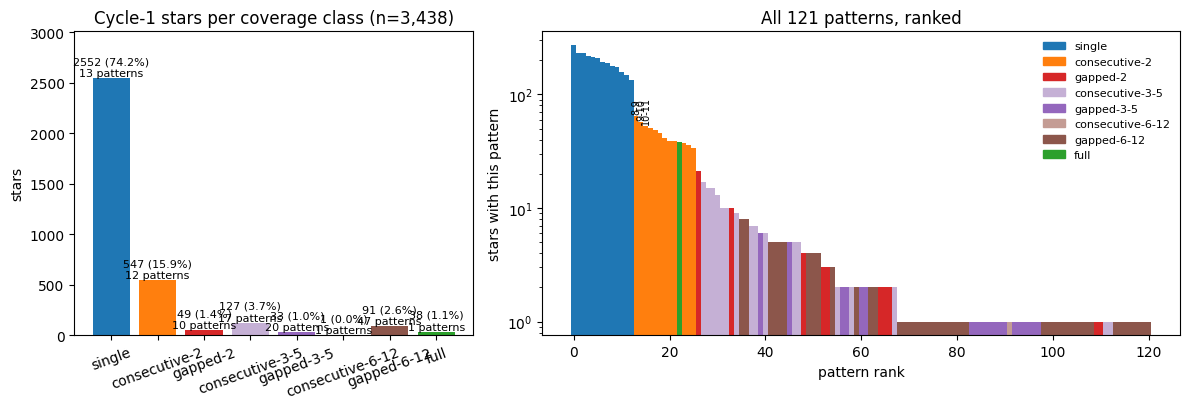

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1, 1.6]))
x = np.arange(len(summary))
a1.bar(x, summary.stars, color=[CLASS_COLORS[c] for c in summary.index])
for i, (n, p, f) in enumerate(zip(summary.stars, summary.patterns, summary.frac_stars)):
    a1.text(i, n, f"{n} ({f:.1%})\n{p} patterns", ha="center", va="bottom", fontsize=8)
a1.set_xticks(x, summary.index, rotation=20)
a1.set_ylabel("stars"); a1.set_ylim(0, summary.stars.max() * 1.18)
a1.set_title("Cycle-1 stars per coverage class (n=3,438)")
ranked = lib.sort_values("n_stars", ascending=False).reset_index(drop=True)
a2.bar(ranked.index, ranked.n_stars, color=[CLASS_COLORS[c] for c in ranked["class"]], width=1.0)
a2.set_yscale("log"); a2.set_xlabel("pattern rank"); a2.set_ylabel("stars with this pattern")
for i in range(16):
    if ranked.loc[i, "class"] != "single":
        a2.annotate(ranked.loc[i, "pattern"], (i, ranked.loc[i, "n_stars"]), fontsize=7, rotation=90,
                    xytext=(0, 3), textcoords="offset points", ha="center")
from matplotlib.patches import Patch
a2.legend(handles=[Patch(color=CLASS_COLORS[c], label=c) for c in cov.COVERAGE_CLASSES], frameon=False, fontsize=8); a2.set_title("All 121 patterns, ranked")
fig.tight_layout(); fig.savefig(FIG / "fig1_coverage_library.png", dpi=130)

## 1b. All TESS years (cycles 1-7)

One library per cycle, plus the pooled default (`all_cycles_patterns.csv`). Patterns are numbered from each cycle's first sector. Cycles 4-6 (14-16 sectors) are fitted into the 13-sector SMARTS year by `coverage.fit_to_year`, which shifts or truncates them.

In [5]:
per = {c: cov.load_library(cov.LIBRARY_DIR / f"cycle{c}_patterns.csv") for c in cov.CYCLE_SECTORS}
pooled = cov.load_library()
targets = pd.read_csv(REPO / "target_df_shortform.csv", index_col=0)
rows = {}
for c, l in per.items():
    f = l.groupby("class").n_stars.sum().reindex(cov.COVERAGE_CLASSES).fillna(0)
    raw = cov.cycle_patterns_from_targets(targets, c)
    rows[f"cycle {c} (S{cov.CYCLE_SECTORS[c][0]}-{cov.CYCLE_SECTORS[c][1]})"] = (
        (f / f.sum()).to_dict() | dict(star_seasons=int(f.sum()), patterns=len(l), shifted=int(l.n_shifted.sum()),
                                     truncated=int(l.n_truncated.sum()),
                                     frac_north=float((targets.loc[raw[raw.str.len() > 0].index, "ec_lat"] > 0).mean())))
f = pooled.groupby("class").n_stars.sum().reindex(cov.COVERAGE_CLASSES).fillna(0)
rows["pooled"] = (f / f.sum()).to_dict() | dict(star_seasons=int(f.sum()), patterns=len(pooled),
                                                shifted=int(pooled.n_shifted.sum()), truncated=int(pooled.n_truncated.sum()),
                                                frac_north=np.nan)
cyc_tab = pd.DataFrame(rows).T
cyc_tab.round(3)

,single,consecutive-2,gapped-2,consecutive-3-5,gapped-3-5,consecutive-6-12,gapped-6-12,full,star_seasons,patterns,shifted,truncated,frac_north
cycle 1 (S1-13),0.742,0.159,0.014,0.037,0.010,0.000,0.026,0.011,3438.0,121.0,0.0,0.0,0.000
cycle 2 (S14-26),0.580,0.132,0.047,0.014,0.156,0.003,0.057,0.010,2607.0,201.0,0.0,0.0,1.000
cycle 3 (S27-39),0.731,0.176,0.011,0.033,0.012,0.001,0.026,0.010,3414.0,126.0,0.0,0.0,0.000
cycle 4 (S40-55),0.484,0.248,0.041,0.126,0.062,0.016,0.022,0.000,3206.0,117.0,446.0,610.0,0.833
cycle 5 (S56-69),0.726,0.164,0.010,0.051,0.021,0.016,0.011,0.000,4019.0,116.0,347.0,0.0,0.379
cycle 6 (S70-83),0.518,0.270,0.033,0.017,0.109,0.019,0.034,0.000,3086.0,152.0,404.0,25.0,0.843
cycle 7 (S84-96),0.752,0.145,0.023,0.041,0.011,0.000,0.027,0.000,4006.0,96.0,0.0,0.0,0.360
pooled,0.658,0.183,0.024,0.046,0.048,0.008,0.028,0.004,23776.0,534.0,1197.0,635.0,NaN


In [6]:
print("pooled patterns per class:", pooled.groupby("class").size().reindex(cov.COVERAGE_CLASSES).to_dict())
c1 = set(per[1].pattern)
print("pooled patterns never seen in Cycle 1:", int((~pooled.pattern.isin(c1)).sum()),
      "| star-seasons in them:", int(pooled.loc[~pooled.pattern.isin(c1), "n_stars"].sum()))
print("patterns by number of cycles they occur in:", pooled.n_cycles.value_counts().sort_index().to_dict())

pooled patterns per class: {'single': 13, 'consecutive-2': 12, 'gapped-2': 39, 'consecutive-3-5': 24, 'gapped-3-5': 203, 'consecutive-6-12': 11, 'gapped-6-12': 231, 'full': 1}
pooled patterns never seen in Cycle 1: 413 | star-seasons in them: 2174
patterns by number of cycles they occur in: {1: 361, 2: 89, 3: 32, 4: 13, 5: 12, 6: 7, 7: 20}


**Figure 1b.** Left: class mix per cycle (fraction of star-seasons) with the hemisphere mix. Right: distinct patterns per class, Cycle 1 vs pooled. Uniform-within-class sampling draws from the right-hand counts.

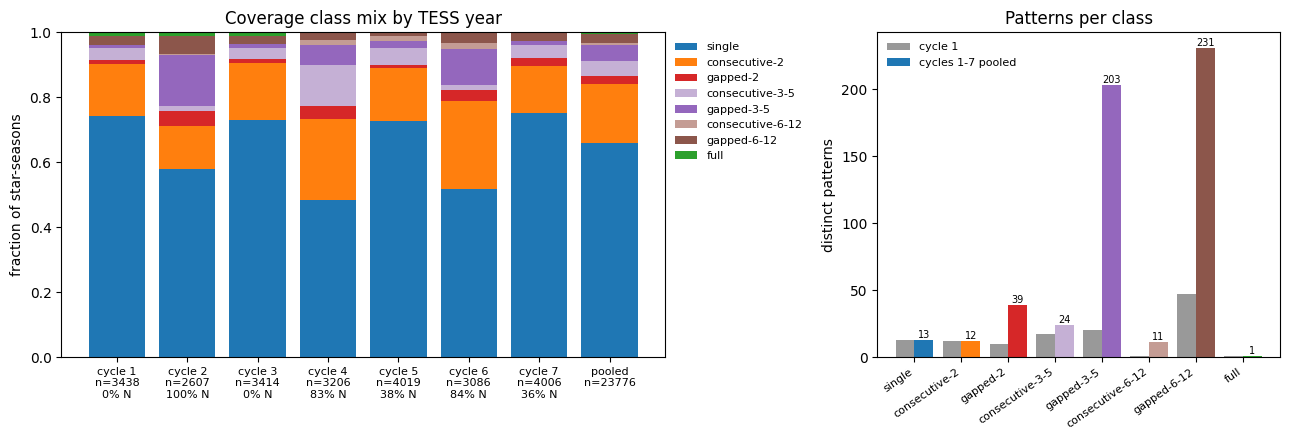

In [7]:
from matplotlib.patches import Patch
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw=dict(width_ratios=[1.5, 1]))
names = list(cyc_tab.index)
bottom = np.zeros(len(names))
for c in cov.COVERAGE_CLASSES:
    a1.bar(range(len(names)), cyc_tab[c].astype(float), bottom=bottom, color=CLASS_COLORS[c], label=c)
    bottom += cyc_tab[c].to_numpy(float)
lbl = [f"{n.split(' (')[0]}\nn={int(r.star_seasons)}" + (f"\n{r.frac_north:.0%} N" if np.isfinite(r.frac_north) else "")
       for n, r in cyc_tab.iterrows()]
a1.set_xticks(range(len(names)), lbl, fontsize=8)
a1.set_ylabel("fraction of star-seasons"); a1.set_title("Coverage class mix by TESS year")
a1.legend(bbox_to_anchor=(1.0, 1), loc="upper left", frameon=False, fontsize=8)
x = np.arange(len(cov.COVERAGE_CLASSES))
n1 = per[1].groupby("class").size().reindex(cov.COVERAGE_CLASSES).fillna(0)
na = pooled.groupby("class").size().reindex(cov.COVERAGE_CLASSES).fillna(0)
a2.bar(x - 0.2, n1, 0.4, color="0.6", label="cycle 1")
a2.bar(x + 0.2, na, 0.4, color=[CLASS_COLORS[c] for c in cov.COVERAGE_CLASSES], label="cycles 1-7 pooled")
for i, v in enumerate(na):
    a2.text(i + 0.2, v, int(v), ha="center", va="bottom", fontsize=7)
a2.set_xticks(x, cov.COVERAGE_CLASSES, rotation=35, ha="right", fontsize=8)
a2.set_ylabel("distinct patterns"); a2.set_title("Patterns per class"); a2.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig1b_coverage_by_cycle.png", dpi=130)

## 2. The default output is unchanged

`--coverage full` (the default) on `synthetic:n=200,seed=0`, compared with the committed baseline tables (`tools/compare_runs.py`) and goals (`check_goals.py`).

In [8]:
print((DATA / "compare_full200_vs_baseline.txt").read_text())
print("\n".join((DATA / "check_goals_full200.txt").read_text().splitlines()[-16:]))

200 stars in common
final_period differs: 0 stars
final_outcome differs: 0 stars
  acf_fft                top1 differs:   0   n_candidates differs:   0
  acf_fft_highpass       top1 differs:   0   n_candidates differs:   0
  acf_fft_short          top1 differs:   0   n_candidates differs:   0
  lombscargle            top1 differs:   0   n_candidates differs:   0
  lombscargle_short      top1 differs:   0   n_candidates differs:   0
  pairwise_histogram     top1 differs:   0   n_candidates differs:   0
  wavelet                top1 differs:   2   n_candidates differs:   3
DIFFERENT


Regression guard (fail if a metric drops by more than its limit):
   base     new   delta  limit  metric
  0.725   0.725  +0.000  0.020  final.overall.success
  0.689   0.689  +0.000  0.060  final.by_bin.1-3d.success
  0.767   0.767  +0.000  0.060  final.by_bin.10-30d.success
  0.861   0.861  +0.000  0.060  final.by_bin.3-10d.success
  0.647   0.647  +0.000  0.060  final.by_bin.<1d.success
  0.750   0.750  

The wavelet-only differences are the known run-to-run residue from TASKS.md P4. They are wavelet candidate counts on stars 00038, 00058 and 00158, plus top-1 shifts of at most 1.5e-10 relative (same outcome). Wavelet isn't pooled into the fit, so final answers are unaffected. The same code gave star 00058 6, 7 or 8 wavelet candidates in different invocations, while pristine `main` gave 6 every time (README, "What didn't work").

## 3. Demo runs: outcome vs coverage

**These runs predate the all-cycles default library and the T18 merge.** They used the Cycle-1 library and the pre-split class names. Classes are recomputed below from each star's `sectors` with the current `coverage_class`. These runs illustrate the infrastructure for T16b; they aren't conclusions. All use the same 100 synthetic stars (`make_suite(100, seed=0)` = the first 100 of the n=200 suite). Only the coverage differs. `full` is those 100 stars, taken from the n=200 full run.

In [9]:
runs = {}
full = pd.read_csv(DATA / "full200" / "per_star.csv")
runs["full\n(first 100 of n=200)"] = full[full.star_id.str[-5:].astype(int) < 100]
for r in ("single", "gapped-2", "real-weighted"):
    runs[r] = pd.read_csv(DATA / r / "per_star.csv", dtype={"sectors": str})
for k in runs:  # re-derive classes with the 2026-10-15 consecutive/gapped split
    runs[k] = runs[k].assign(coverage_class=runs[k].sectors.astype(str).map(lambda p: cov.coverage_class(cov.parse_pattern(p))))
rw = runs["real-weighted"]
groups = dict(runs)
for c in cov.COVERAGE_CLASSES:
    sub = rw[rw.coverage_class == c]
    if len(sub):
        groups[f"real-weighted:\n{c}"] = sub
tab = pd.DataFrame({k.replace("\n", " "): ev.outcome_fractions(v.final_outcome) for k, v in groups.items()}).T
tab[["n", "success", "correct", "diffrot", "alias", "wrong", "none"]].round(3)

,n,success,correct,diffrot,alias,wrong,none
full (first 100 of n=200),100.0,0.690,0.440,0.250,0.020,0.080,0.210
single,100.0,0.280,0.150,0.130,0.040,0.360,0.320
gapped-2,100.0,0.300,0.180,0.120,0.020,0.440,0.240
real-weighted,100.0,0.330,0.190,0.140,0.040,0.370,0.260
real-weighted: single,69.0,0.246,0.130,0.116,0.043,0.391,0.319
real-weighted: consecutive-2,15.0,0.467,0.333,0.133,0.000,0.333,0.200
real-weighted: gapped-2,1.0,0.000,0.000,0.000,0.000,0.000,1.000
real-weighted: consecutive-3-5,9.0,0.444,0.222,0.222,0.111,0.444,0.000
real-weighted: gapped-6-12,4.0,0.750,0.250,0.500,0.000,0.250,0.000
real-weighted: full,2.0,1.000,1.000,0.000,0.000,0.000,0.000


**Figure 2.** Final outcome by coverage. Left: the four runs. Right: the real-weighted run split by each star's sampled class (small n except `single`).

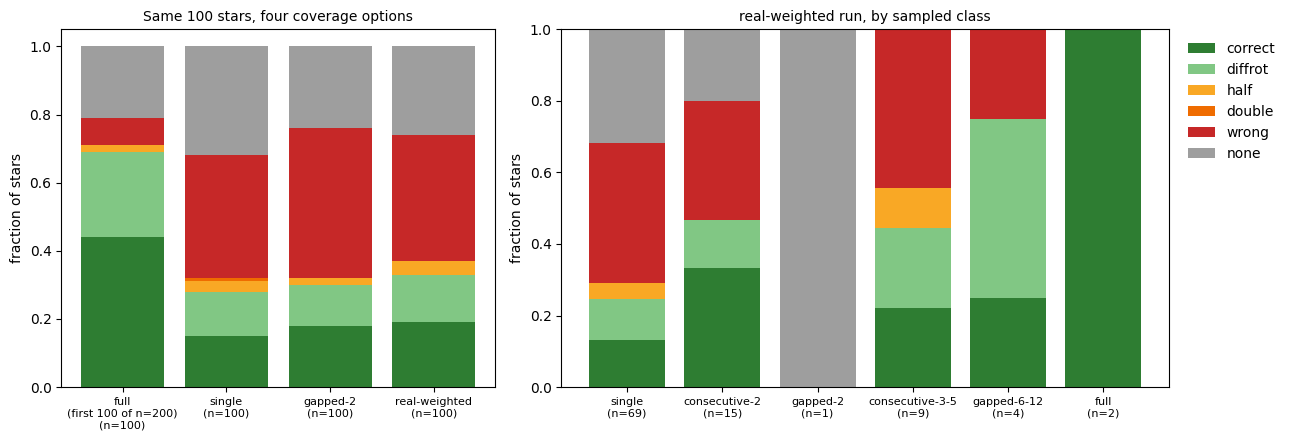

In [10]:
def stacked(ax, items, title):
    names = list(items)
    bottom = np.zeros(len(names))
    for o in ev.OUTCOMES:
        vals = np.array([np.mean(items[k].final_outcome == o) for k in names])
        ax.bar(range(len(names)), vals, bottom=bottom, color=OUTCOME_COLORS[o], label=o)
        bottom += vals
    ax.set_xticks(range(len(names)), [f"{k}\n(n={len(items[k])})" for k in names], fontsize=8)
    ax.set_ylabel("fraction of stars"); ax.set_title(title, fontsize=10)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw=dict(width_ratios=[1, 1.4]))
stacked(a1, runs, "Same 100 stars, four coverage options")
stacked(a2, {c: rw[rw.coverage_class == c] for c in cov.COVERAGE_CLASSES if (rw.coverage_class == c).any()},
        "real-weighted run, by sampled class")
a2.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig2_outcome_vs_coverage.png", dpi=130)

**Figure 3.** Success by period bin for each run (same 100 stars).

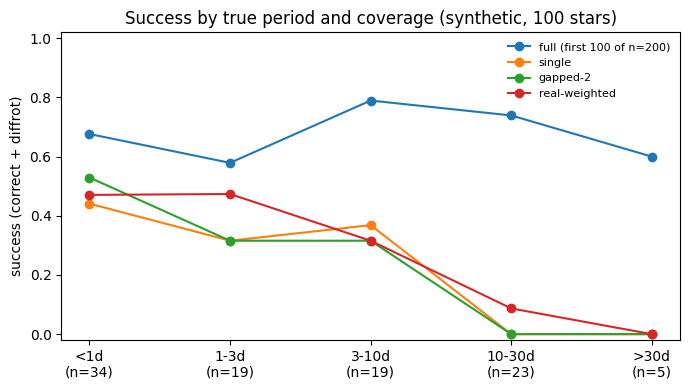

In [11]:
bins = [b for b in ev.PERIOD_BIN_LABELS]
fig, ax = plt.subplots(figsize=(7, 4))
for k, v in runs.items():
    s = [v[v.period_bin == b].final_outcome.isin(ev.SUCCESS_OUTCOMES).mean() if (v.period_bin == b).any() else np.nan for b in bins]
    ax.plot(bins, s, marker="o", label=k.replace("\n", " "))
n = runs["single"].period_bin.value_counts()
ax.set_xticks(range(len(bins)), [f"{b}\n(n={n.get(b, 0)})" for b in bins])
ax.set_ylabel("success (correct + diffrot)"); ax.set_ylim(-0.02, 1.02); ax.legend(frameon=False, fontsize=8)
ax.set_title("Success by true period and coverage (synthetic, 100 stars)")
fig.tight_layout(); fig.savefig(FIG / "fig3_success_by_bin_and_coverage.png", dpi=130)

**Figure 4.** Outcome against the coverage descriptors: true period over the longest contiguous stretch, for every star in the three patchy runs. This is T16c's axis.

final_outcome,correct,diffrot,double,half,none,wrong
p_over_span,,,,,,
"(0.0, 0.03]",0.23,0.26,0.01,0.09,0.26,0.15
"(0.03, 0.1]",0.20,0.17,NaN,NaN,0.30,0.33
"(0.1, 0.333]",0.26,0.07,NaN,NaN,0.26,0.41
"(0.333, 1.0]",0.04,NaN,NaN,NaN,0.31,0.65
"(1.0, 100.0]",NaN,NaN,NaN,NaN,0.19,0.81


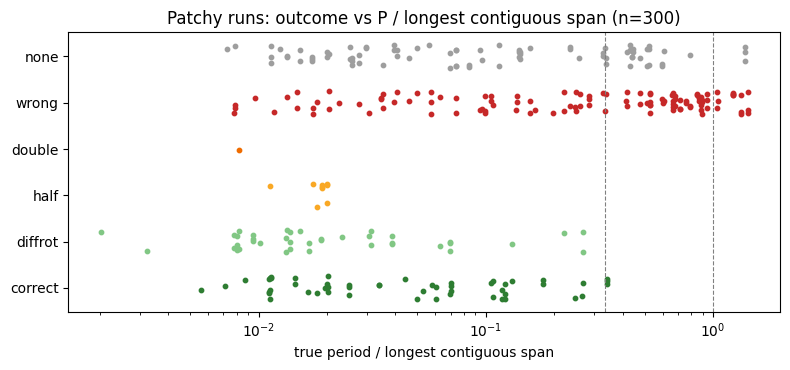

In [12]:
pat = pd.concat([runs[r].assign(run=r) for r in ("single", "gapped-2", "real-weighted")])
pat["p_over_span"] = pat.true_period / pat.longest_contiguous_days
fig, ax = plt.subplots(figsize=(8, 3.8))
order = list(ev.OUTCOMES)
rng = np.random.default_rng(0)
for o in order:
    s = pat[pat.final_outcome == o]
    ax.scatter(s.p_over_span, order.index(o) + rng.uniform(-0.25, 0.25, len(s)), s=10, color=OUTCOME_COLORS[o])
ax.set_xscale("log"); ax.set_yticks(range(len(order)), order)
for xv in (1/3, 1):
    ax.axvline(xv, color="0.5", ls="--", lw=0.8)
ax.set_xlabel("true period / longest contiguous span"); ax.set_title("Patchy runs: outcome vs P / longest contiguous span (n=300)")
fig.tight_layout(); fig.savefig(FIG / "fig4_outcome_vs_p_over_span.png", dpi=130)
pat.groupby(pd.cut(pat.p_over_span, [0, 0.03, 0.1, 1/3, 1, 100]), observed=True).final_outcome.value_counts(normalize=True).unstack().round(2)

## 4. Failure mode: short confident wrong answers on single sectors

In the single-sector run, 36 of 100 stars are `wrong`, and every one of those answers is below 0.5 d. This looks like open issues 10/15 (low-SNR stars getting ~0.2–0.5 d answers that pass the gates), much amplified on short data. It isn't only low SNR: 10 of the 36 have SNR > 5.

In [13]:
s = runs["single"]
w = s[s.final_outcome == "wrong"]
print("wrong final periods:", w.final_period.describe().round(3).to_dict())
print(pd.crosstab(pd.cut(s.meta_snr, [0, 2, 5, 20]), s.final_outcome))

wrong final periods: {'count': 36.0, 'mean': 0.221, 'std': 0.069, 'min': 0.132, '25%': 0.175, '50%': 0.206, '75%': 0.243, 'max': 0.416}
final_outcome  correct  diffrot  double  half  none  wrong
meta_snr                                                  
(0, 2]               4        3       0     0     9      8
(2, 5]               7        5       0     0    10     18
(5, 20]              4        5       1     3    13     10


**Figure 5.** Three single-sector `wrong` stars, regenerated exactly: one each at low, mid and high SNR. Left: light curve. Right: gap-aware ACF with the true P (green), the chosen P (red) and its multiples.

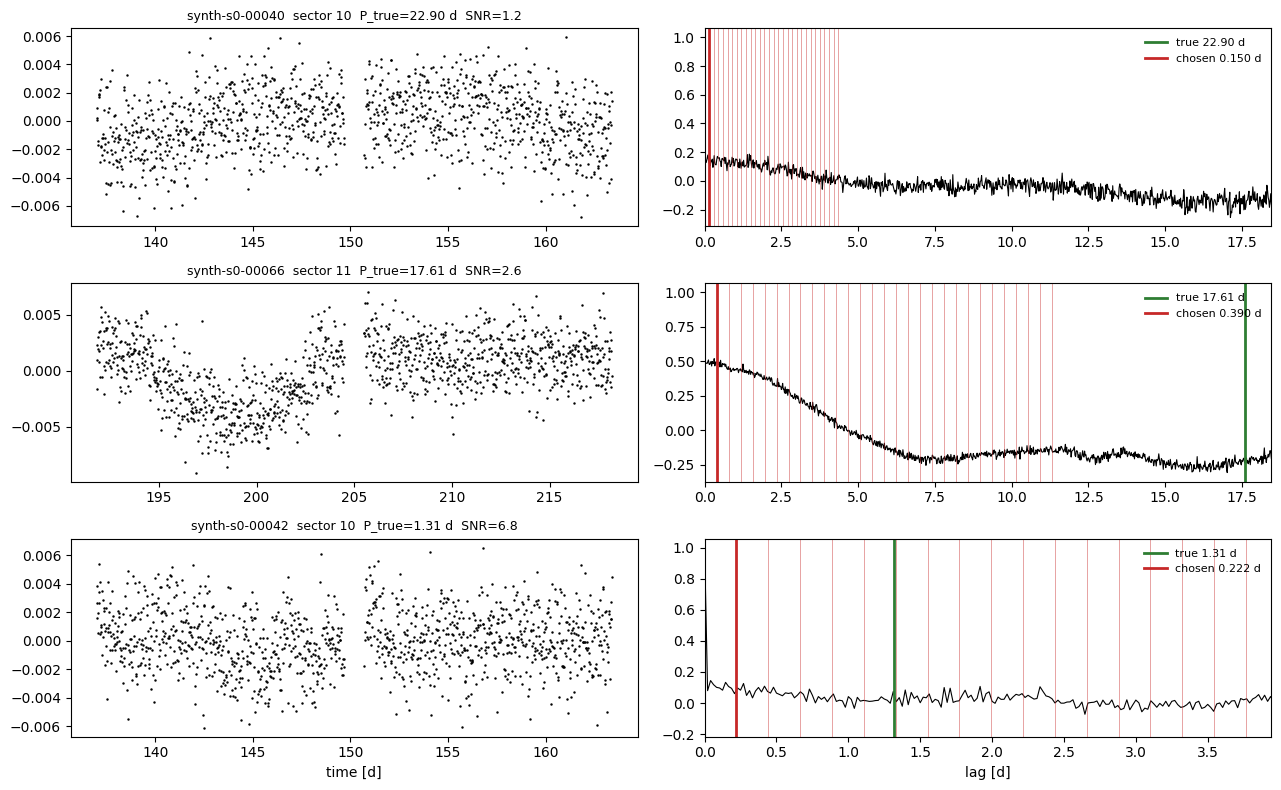

In [14]:
from synthetic import make_suite
from acf_utils import compute_acf
pats = cov.sample_patterns("single", 100, seed=0)
suite = {lc.star_id: lc for lc in make_suite(100, seed=0, sectors=pats)}
picks = []
for lo, hi in [(0, 2), (2, 5), (5, 20)]:
    cand = w[(w.meta_snr > lo) & (w.meta_snr <= hi)].sort_values("true_period")
    picks.append(cand.iloc[len(cand) // 2])
fig, axes = plt.subplots(3, 2, figsize=(13, 8))
for (a1, a2), r in zip(axes, picks):
    lc = suite[r.star_id]
    a1.plot(lc.time, lc.flux, ".", ms=1.5, color="k")
    a1.set_title(f"{r.star_id}  sector {r.sectors}  P_true={r.true_period:.2f} d  SNR={r.meta_snr:.1f}", fontsize=9)
    lags, acf = compute_acf(lc.time, lc.flux)
    a2.plot(lags, acf, color="k", lw=0.8)
    for k in range(1, 30):
        if k * r.final_period < lags.max():
            a2.axvline(k * r.final_period, color="#c62828", lw=0.5, alpha=0.6)
    a2.axvline(r.true_period, color="#2e7d32", lw=2, label=f"true {r.true_period:.2f} d")
    a2.axvline(r.final_period, color="#c62828", lw=2, label=f"chosen {r.final_period:.3f} d")
    a2.set_xlim(0, min(lags.max(), max(3 * r.true_period, 3)))
    a2.legend(fontsize=8, frameon=False)
axes[-1, 0].set_xlabel("time [d]"); axes[-1, 1].set_xlabel("lag [d]")
fig.tight_layout(); fig.savefig(FIG / "fig5_single_sector_wrong_examples.png", dpi=130)

## 5. Runtime

Median seconds per star (2 workers on the i5).

In [15]:
pd.Series({r: json.load(open(DATA / r / "metrics.json"))["runtime"]["median_seconds"]
           for r in ("full200", "single", "gapped-2", "real-weighted")}).round(2)

full200          3.51
single           0.62
gapped-2         0.90
real-weighted    1.00
dtype: float64